# 🔬 ResNet-18 FAF Classifier — Inference Demo

This notebook loads the trained **ResNet-18** model (3 classes: **Choroiditis**, **Normal**, **Scar**) and runs inference on **15 randomly selected images** from the dataset.

For each image we display:
- The synthetic FAF image
- The **true** (ground-truth) class
- The **predicted** class with confidence %
- ✅ / ❌ indicator

In [7]:
import os
import random
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

print("All imports successful ✅")

All imports successful ✅


In [8]:
# ==========================================
# CONFIGURATION
# ==========================================
DATA_DIR   = r"C:\Users\ashut\BE_Project\Dataset\Generated_FAF_CNN_Dataset_Refactored_3classes"
WEIGHTS    = r"C:\Users\ashut\BE_Project\Codes\Training\Training_3_classes\best_resnet_faf_classifier.pth"
NUM_IMAGES = 15  # number of images to demo

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [9]:
# ==========================================
# LOAD THE TRAINED MODEL
# ==========================================

# Class names (must match the folder order used during training)
class_names = sorted(os.listdir(DATA_DIR))
num_classes = len(class_names)
print(f"Classes ({num_classes}): {class_names}")

# Build the same architecture used for training
model = models.resnet18(weights=None)   # no pretrained weights — we load our own
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, num_classes)

# Load trained weights
model.load_state_dict(torch.load(WEIGHTS, map_location=device))
model = model.to(device)
model.eval()

print("\n✅ Model loaded and set to eval mode!")

Classes (3): ['Choroiditis', 'Normal', 'Scar']

✅ Model loaded and set to eval mode!


C:\Users\ashut\AppData\Local\Temp\ipykernel_17244\2936689589.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(WEIGHTS, map_location=devi

In [10]:
# ==========================================
# TRANSFORMS  (same as validation transforms)
# ==========================================
inference_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# ImageNet de-normalisation for display
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

print("Transforms ready ✅")

Transforms ready ✅


In [11]:
# ==========================================
# GATHER ALL IMAGE PATHS + TRUE LABELS
# ==========================================
all_images = []  # list of (filepath, class_name)

for cls in class_names:
    cls_dir = os.path.join(DATA_DIR, cls)
    for fname in os.listdir(cls_dir):
        if fname.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff')):
            all_images.append((os.path.join(cls_dir, fname), cls))

print(f"Total images found: {len(all_images)}")

# Pick NUM_IMAGES random samples
random.seed(None)  # truly random each run
selected = random.sample(all_images, min(NUM_IMAGES, len(all_images)))
print(f"Selected {len(selected)} images for demo")

Total images found: 62
Selected 15 images for demo


C:\Users\ashut\AppData\Local\Temp\ipykernel_17244\1150655273.py:103: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])
C:\Users\ashut\AppData\Local\Temp\ipykernel_17244\1150655273.py:104: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.savefig("inference_results.png", dpi=150, facecolor=BG_COLOR,
C:\Users\ashut\AppData\Local\Temp\ipykernel_17244\1150655273.py:104: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.savefig("inference_results.png", dpi=150, facecolor=BG_COLOR,


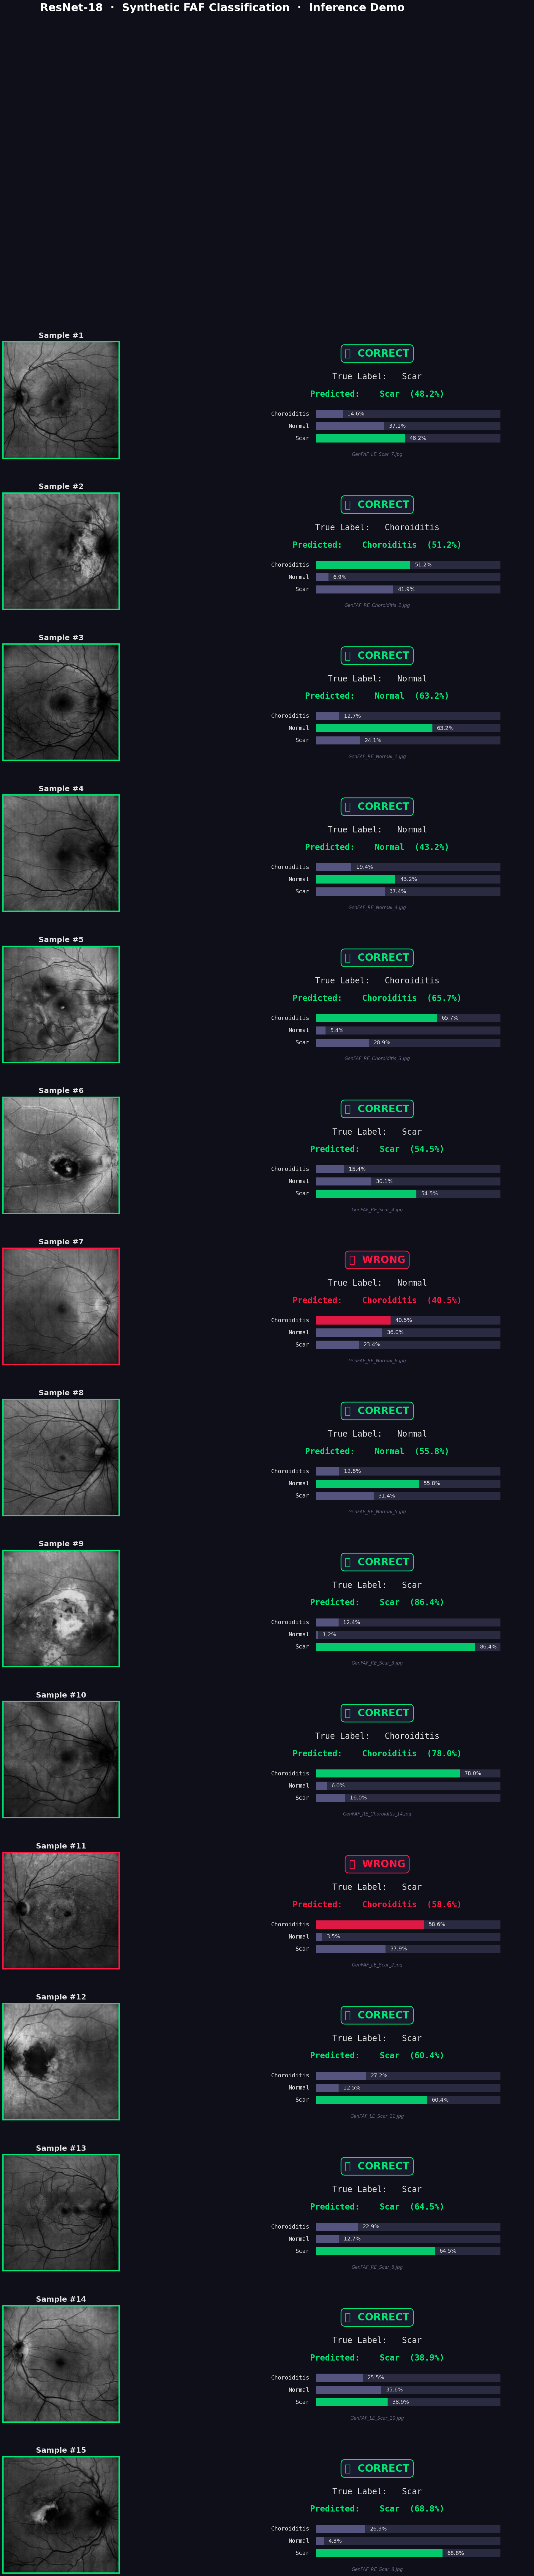


  Overall: 13/15 correct  (87%)


In [12]:
# ==========================================
# RUN INFERENCE & DISPLAY RESULTS
# ==========================================

# ---------- colour palette ----------
BG_COLOR   = "#0f0f1a"
CARD_COLOR = "#1a1a2e"
CORRECT_COLOR  = "#00e676"   # green
WRONG_COLOR    = "#ff1744"   # red
TEXT_COLOR     = "#e0e0e0"

fig = plt.figure(figsize=(26, 6.5 * NUM_IMAGES), facecolor=BG_COLOR)
gs  = gridspec.GridSpec(NUM_IMAGES, 2, width_ratios=[1, 1.2],
                        hspace=0.30, wspace=0.12)

correct_count = 0

for idx, (img_path, true_class) in enumerate(selected):
    # --- Load & preprocess ---
    pil_img = Image.open(img_path).convert("RGB")
    tensor  = inference_transforms(pil_img).unsqueeze(0).to(device)

    # --- Predict ---
    with torch.no_grad():
        logits = model(tensor)
        probs  = torch.softmax(logits, dim=1).squeeze().cpu().numpy()

    pred_idx   = int(np.argmax(probs))
    pred_class = class_names[pred_idx]
    confidence = probs[pred_idx] * 100
    is_correct = pred_class == true_class
    if is_correct:
        correct_count += 1

    accent = CORRECT_COLOR if is_correct else WRONG_COLOR
    emoji  = "✅" if is_correct else "❌"

    # -------- LEFT: image --------
    ax_img = fig.add_subplot(gs[idx, 0])
    ax_img.imshow(pil_img)
    ax_img.set_xticks([])
    ax_img.set_yticks([])
    for spine in ax_img.spines.values():
        spine.set_edgecolor(accent)
        spine.set_linewidth(3)
    ax_img.set_facecolor(CARD_COLOR)
    ax_img.set_title(f"Sample #{idx+1}", fontsize=18,
                     color=TEXT_COLOR, fontweight="bold", pad=10)

    # -------- RIGHT: info panel --------
    ax_info = fig.add_subplot(gs[idx, 1])
    ax_info.set_xlim(0, 10)
    ax_info.set_ylim(0, 10)
    ax_info.axis("off")
    ax_info.set_facecolor(CARD_COLOR)

    # Result badge
    ax_info.text(5, 9.0, f"{emoji}  {'CORRECT' if is_correct else 'WRONG'}",
                ha="center", va="center", fontsize=24, fontweight="bold",
                color=accent,
                bbox=dict(boxstyle="round,pad=0.4", facecolor=CARD_COLOR,
                          edgecolor=accent, linewidth=2))

    # True label
    ax_info.text(5, 7.0, f"True Label:   {true_class}",
                ha="center", va="center", fontsize=20, color=TEXT_COLOR,
                fontfamily="monospace")

    # Predicted label
    ax_info.text(5, 5.5, f"Predicted:    {pred_class}  ({confidence:.1f}%)",
                ha="center", va="center", fontsize=20, color=accent,
                fontfamily="monospace", fontweight="bold")

    # Confidence bars for all classes
    bar_y_start = 3.8
    bar_h = 0.7
    for ci, cname in enumerate(class_names):
        y = bar_y_start - ci * (bar_h + 0.35)
        # Background bar
        ax_info.barh(y, 6, left=3.0, height=bar_h, color="#2a2a40",
                     edgecolor="none", zorder=1)
        # Filled bar
        bar_color = accent if ci == pred_idx else "#5c5c8a"
        ax_info.barh(y, 6 * probs[ci], left=3.0, height=bar_h,
                     color=bar_color, edgecolor="none", zorder=2, alpha=0.85)
        # Class name on the left
        ax_info.text(2.8, y, cname, ha="right", va="center",
                     fontsize=14, color=TEXT_COLOR, fontfamily="monospace")
        # Percentage on the bar
        ax_info.text(3.0 + 6 * probs[ci] + 0.15, y,
                     f"{probs[ci]*100:.1f}%", ha="left", va="center",
                     fontsize=13, color=TEXT_COLOR)

    # Filename
    fname = os.path.basename(img_path)
    ax_info.text(5, 0.3, fname, ha="center", va="center",
                fontsize=11, color="#666680", fontstyle="italic")

# ---- Overall title ----
fig.suptitle("ResNet-18  ·  Synthetic FAF Classification  ·  Inference Demo",
             fontsize=26, color="white", fontweight="bold", y=0.997)

plt.tight_layout(rect=[0, 0, 1, 0.99])
plt.savefig("inference_results.png", dpi=150, facecolor=BG_COLOR,
            bbox_inches="tight")
plt.show()

print(f"\n{'='*50}")
print(f"  Overall: {correct_count}/{len(selected)} correct  "
      f"({100*correct_count/len(selected):.0f}%)")
print(f"{'='*50}")